In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import norm, chi2_contingency
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

df = pd.read_csv("checkout_ab_test_v2.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (1200, 8)


,VisitorID,Variant,Timestamp,Device,TrafficSource,CheckoutStarted,Converted,OrderValueINR
0,VIS-00001,A,2026-07-10T14:33:00,Tablet,Paid,Yes,No,0
1,VIS-00002,B,2026-07-01T13:41:00,Tablet,Paid,No,No,0
2,VIS-00003,A,2026-07-18T04:55:00,Tablet,Paid,No,No,0
3,VIS-00004,B,2026-07-17T22:45:00,Desktop,Paid,No,No,0
4,VIS-00005,A,2026-07-17T23:44:00,Mobile,Direct,Yes,No,0


In [3]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nUnique Visitors:", df["VisitorID"].nunique())

print("\nVariant Distribution:")
print(df["Variant"].value_counts())

print("\nConversion Distribution:")
print(df["Converted"].value_counts())

print("\nCheckout Started Distribution:")
print(df["CheckoutStarted"].value_counts())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (1200, 8)

Missing Values:
VisitorID          0
Variant            0
Timestamp          0
Device             0
TrafficSource      0
CheckoutStarted    0
Converted          0
OrderValueINR      0
dtype: int64

Duplicate Rows: 0

Unique Visitors: 1200

Variant Distribution:
Variant
A    600
B    600
Name: count, dtype: int64

Conversion Distribution:
Converted
No     1072
Yes     128
Name: count, dtype: int64

Checkout Started Distribution:
CheckoutStarted
No     820
Yes    380
Name: count, dtype: int64

Data Types:
VisitorID            str
Variant              str
Timestamp            str
Device               str
TrafficSource        str
CheckoutStarted      str
Converted            str
OrderValueINR      int64
dtype: object


Null Hypothesis (H₀): There is no significant difference in conversion rates between Control A and Variant B.

Alternative Hypothesis (H₁): There is a significant difference in conversion rates between Control A and Variant B.

We will use a two-tailed test with a 5% significance level (α = 0.05).

In [4]:
# Calculate performance for each variant

results = df.groupby("Variant").agg(
    Total_Visitors=("VisitorID", "count"),
    Conversions=("Converted", lambda x: (x == "Yes").sum())
)

results["Non_Conversions"] = (
    results["Total_Visitors"] - results["Conversions"]
)

results["Conversion_Rate"] = (
    results["Conversions"] / results["Total_Visitors"] * 100
)

display(results)

,Total_Visitors,Conversions,Non_Conversions,Conversion_Rate
Variant,,,,
A,600,57,543,9.500000
B,600,71,529,11.833333


In [5]:
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.proportion import confint_proportions_2indep

# Conversion counts
conversions_A = 57
conversions_B = 71

visitors_A = 600
visitors_B = 600

# Two-proportion Z-test
counts = [conversions_B, conversions_A]
nobs = [visitors_B, visitors_A]

z_stat, p_value = proportions_ztest(
    counts, nobs, alternative="two-sided"
)

# Conversion rate difference: B - A
rate_A = conversions_A / visitors_A
rate_B = conversions_B / visitors_B

lift = rate_B - rate_A

# 95% Confidence Interval for difference
ci_low, ci_high = confint_proportions_2indep(
    conversions_B, visitors_B,
    conversions_A, visitors_A,
    method="newcomb",
    alpha=0.05
)

print("Z-Statistic:", round(z_stat, 4))
print("P-Value:", round(p_value, 4))

print("Conversion Lift:", round(lift * 100, 2), "percentage points")

print(
    "95% Confidence Interval:",
    round(ci_low * 100, 2), "%",
    "to",
    round(ci_high * 100, 2), "%"
)

if p_value < 0.05:
    print("Decision: Reject the Null Hypothesis")
else:
    print("Decision: Fail to Reject the Null Hypothesis")

Z-Statistic: 1.3092
P-Value: 0.1905
Conversion Lift: 2.33 percentage points
95% Confidence Interval: -1.18 % to 5.85 %
Decision: Fail to Reject the Null Hypothesis


In [6]:
from statsmodels.stats.proportion import proportion_effectsize

# Cohen's h effect size
cohens_h = proportion_effectsize(rate_B, rate_A)

# Relative conversion lift
relative_lift = ((rate_B - rate_A) / rate_A) * 100

print("Cohen's h:", round(cohens_h, 4))
print("Relative Conversion Lift:", round(relative_lift, 2), "%")

if abs(cohens_h) < 0.2:
    print("Effect Size: Small")
elif abs(cohens_h) < 0.5:
    print("Effect Size: Medium")
else:
    print("Effect Size: Large")

Cohen's h: 0.0757
Relative Conversion Lift: 24.56 %
Effect Size: Small


# Executive Decision Memo: Website Checkout A/B Test

## 1. Experiment Overview
A website checkout experiment was conducted to compare the existing checkout experience (Control A) against a modified experience (Variant B).

- Total visitors: 1,200
- Control A: 600 visitors
- Variant B: 600 visitors
- Significance level: 5%
- Statistical method: Two-Proportion Z-Test

## 2. Key Results

| Metric | Control A | Variant B |
|---|---:|---:|
| Visitors | 600 | 600 |
| Conversions | 57 | 71 |
| Conversion Rate | 9.50% | 11.83% |

- Absolute conversion lift: +2.33 percentage points
- Relative conversion lift: +24.56%
- Z-statistic: 1.3092
- P-value: 0.1905
- 95% Confidence Interval: -1.18 to +5.85 percentage points
- Cohen's h: 0.0757 (Small effect)

## 3. Statistical Conclusion

The p-value (0.1905) is greater than the significance level (0.05). The 95% confidence interval includes zero.

Therefore, we fail to reject the null hypothesis. The experiment does not provide sufficient statistical evidence that Variant B improves checkout conversion.

## 4. Business Recommendation

**Recommendation: Keep Control A for now.**

Although Variant B recorded a higher observed conversion rate, the improvement is not statistically significant. Launching Variant B as the proven better experience would be premature.

Recommended next actions:
1. Retain the existing Control A experience.
2. Plan a follow-up experiment with an appropriate sample size.
3. Define the minimum practically meaningful conversion improvement before running the next test.
4. Monitor conversion performance across device types and traffic sources.

## 5. Final Decision

Variant B shows a promising numerical improvement, but the available evidence is inconclusive. A larger, properly planned experiment is required before making a permanent rollout decision.

**Decision: Do not declare Variant B the winner based on this experiment.**

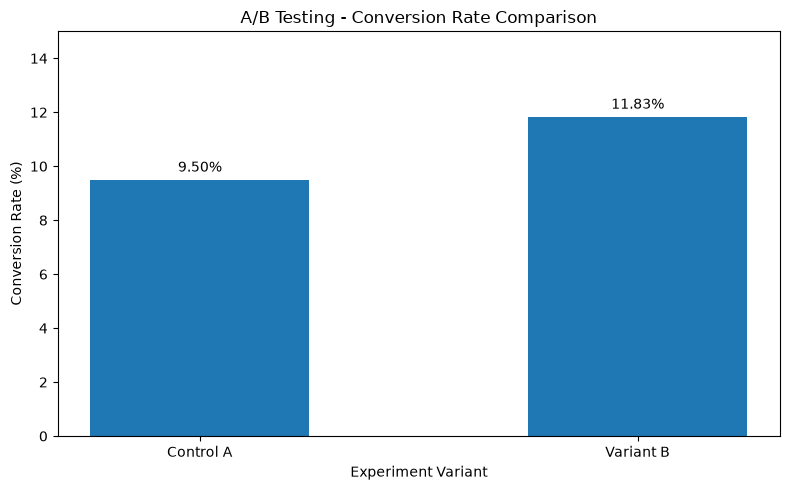

In [7]:
import matplotlib.pyplot as plt

variants = ["Control A", "Variant B"]
conversion_rates = [rate_A * 100, rate_B * 100]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    variants,
    conversion_rates,
    width=0.5
)

plt.title("A/B Testing - Conversion Rate Comparison")
plt.xlabel("Experiment Variant")
plt.ylabel("Conversion Rate (%)")
plt.ylim(0, 15)

for bar, value in zip(bars, conversion_rates):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("ab_conversion_comparison.png", dpi=300)
plt.show()

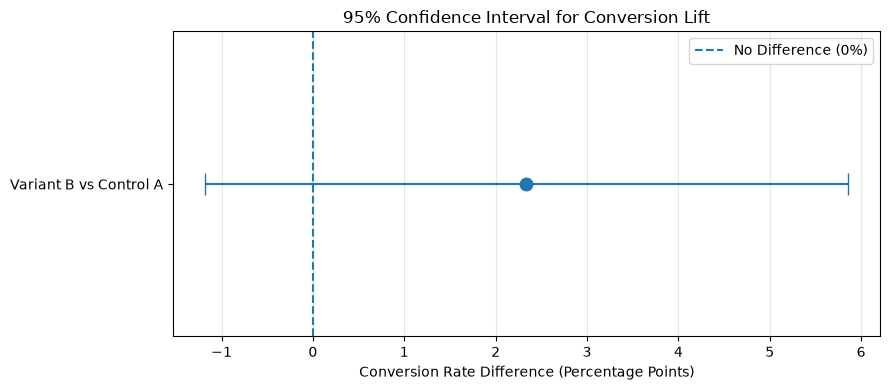

In [8]:
import matplotlib.pyplot as plt

ci_lower = ci_low * 100
ci_upper = ci_high * 100
observed_lift = lift * 100

plt.figure(figsize=(9, 4))

plt.errorbar(
    observed_lift,
    1,
    xerr=[[
        observed_lift - ci_lower
    ], [
        ci_upper - observed_lift
    ]],
    fmt="o",
    capsize=8,
    markersize=9
)

plt.axvline(0, linestyle="--", label="No Difference (0%)")

plt.yticks([1], ["Variant B vs Control A"])
plt.xlabel("Conversion Rate Difference (Percentage Points)")
plt.title("95% Confidence Interval for Conversion Lift")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig("ab_confidence_interval.png", dpi=300)
plt.show()

In [9]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

effect_size = proportion_effectsize(rate_B, rate_A)

power_analysis = NormalIndPower()

required_sample = power_analysis.solve_power(
    effect_size=abs(effect_size),
    alpha=0.05,
    power=0.80,
    ratio=1.0,
    alternative="two-sided"
)

print("Current Sample Size per Group:", 600)
print("Required Sample Size per Group:", round(required_sample))
print("Required Total Sample Size:", round(required_sample) * 2)

Current Sample Size per Group: 600
Required Sample Size per Group: 2740
Required Total Sample Size: 5480


## Sample Size and Statistical Power Analysis

The experiment included 600 visitors in each group.

Based on the observed conversion rates, approximately 2,740 visitors per group (5,480 total) would be required to detect an effect of this size with 80% statistical power at a 5% significance level.

The current experiment may therefore be underpowered to detect the observed conversion difference.

A larger follow-up experiment is recommended before making a final rollout decision.

In [10]:
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from datetime import date

pdf_name = "AB_Testing_Statistical_Report.pdf"

with PdfPages(pdf_name) as pdf:

    # PAGE 1: Executive Summary
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.text(0.1, 0.94, "A/B TESTING & HYPOTHESIS TESTING",
             fontsize=19, weight="bold")
    fig.text(0.1, 0.90, "Website Checkout Experiment | Statistical Report",
             fontsize=11)

    summary = f"""
EXPERIMENT OVERVIEW

Total Visitors: 1,200
Control A Visitors: 600
Variant B Visitors: 600

HYPOTHESES

H0: There is no significant difference in conversion rates.
H1: There is a significant difference in conversion rates.

CONVERSION PERFORMANCE

Control A: 57 / 600 = 9.50%
Variant B: 71 / 600 = 11.83%

Absolute Conversion Lift: +2.33 percentage points
Relative Conversion Lift: +24.56%

STATISTICAL TEST RESULTS

Test: Two-Proportion Z-Test
Z-Statistic: {z_stat:.4f}
P-Value: {p_value:.4f}
Significance Level: 0.05

95% Confidence Interval:
{ci_low*100:.2f} to {ci_high*100:.2f} percentage points

Effect Size (Cohen's h): {cohens_h:.4f}
Effect Size Category: Small

STATISTICAL DECISION

Fail to Reject the Null Hypothesis.

The observed difference is not statistically significant.
The confidence interval includes zero.
"""
    fig.text(0.1, 0.82, summary, fontsize=11,
             va="top", linespacing=1.55)
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    # PAGE 2: Conversion comparison
    img = plt.imread("ab_conversion_comparison.png")
    fig, ax = plt.subplots(figsize=(8.27, 11.69))
    ax.imshow(img)
    ax.axis("off")
    fig.suptitle("Conversion Rate Comparison",
                 fontsize=17, weight="bold")
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    # PAGE 3: Confidence interval and recommendation
    img = plt.imread("ab_confidence_interval.png")
    fig = plt.figure(figsize=(8.27, 11.69))

    ax = fig.add_axes([0.10, 0.58, 0.80, 0.25])
    ax.imshow(img)
    ax.axis("off")

    fig.text(0.1, 0.48, "BUSINESS RECOMMENDATION",
             fontsize=15, weight="bold")

    recommendation = f"""
Decision: Keep Control A for now.

Variant B recorded a higher observed conversion rate,
but the p-value ({p_value:.4f}) exceeds 0.05.

SAMPLE SIZE ANALYSIS

Current sample: 600 visitors per group
Estimated required sample: 2,740 per group
Estimated total: 5,480 visitors

A larger follow-up experiment is recommended.
The sample-size estimate assumes the observed effect
is the effect we want to detect.

FINAL CONCLUSION

There is insufficient statistical evidence to declare
Variant B the winner. Do not permanently launch B based
on this experiment alone.
"""
    fig.text(0.1, 0.43, recommendation,
             fontsize=11, va="top", linespacing=1.6)

    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

print("PDF Report Created Successfully:", pdf_name)

PDF Report Created Successfully: AB_Testing_Statistical_Report.pdf


In [11]:
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER, TA_LEFT
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table,
    TableStyle, Image, PageBreak, KeepTogether
)

pdf_name = "AB_Testing_Statistical_Report.pdf"

doc = SimpleDocTemplate(
    pdf_name,
    pagesize=A4,
    rightMargin=1.8*cm,
    leftMargin=1.8*cm,
    topMargin=2.0*cm,
    bottomMargin=2.0*cm
)

navy = colors.HexColor("#17365D")
blue = colors.HexColor("#2878B5")
light_blue = colors.HexColor("#EAF2F8")
grey = colors.HexColor("#596579")

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="ReportTitle", parent=styles["Title"],
    fontSize=23, leading=29, textColor=navy,
    alignment=TA_CENTER, spaceAfter=10
))

styles.add(ParagraphStyle(
    name="SubtitleCustom", parent=styles["Normal"],
    fontSize=11, leading=16, textColor=grey,
    alignment=TA_CENTER
))

styles.add(ParagraphStyle(
    name="SectionCustom", parent=styles["Heading2"],
    fontSize=14, leading=19, textColor=navy,
    spaceBefore=12, spaceAfter=8
))

styles.add(ParagraphStyle(
    name="BodyCustom", parent=styles["BodyText"],
    fontSize=9.5, leading=15, spaceAfter=6
))

styles.add(ParagraphStyle(
    name="SmallCustom", parent=styles["BodyText"],
    fontSize=8, leading=11, textColor=grey
))

def footer(canvas, doc):
    canvas.saveState()
    canvas.setStrokeColor(colors.HexColor("#D5DEE8"))
    canvas.line(1.8*cm, 1.45*cm, 19.2*cm, 1.45*cm)
    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(grey)
    canvas.drawString(1.8*cm, 1.05*cm, "S. SHREE VATHY | A/B Testing Analysis")
    canvas.drawRightString(19.2*cm, 1.05*cm, f"Page {doc.page}")
    canvas.restoreState()

def make_table(data, widths):
    table = Table(data, colWidths=widths, repeatRows=1)
    table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), navy),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("FONTNAME", (0, 1), (-1, -1), "Helvetica"),
        ("FONTSIZE", (0, 0), (-1, -1), 9),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.HexColor("#D5DEE8")),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1),
         [colors.white, light_blue]),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("LEFTPADDING", (0, 0), (-1, -1), 9),
        ("RIGHTPADDING", (0, 0), (-1, -1), 9),
        ("TOPPADDING", (0, 0), (-1, -1), 8),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 8),
    ]))
    return table

story = []

# PAGE 1 — COVER AND OVERVIEW
story.append(Spacer(1, 1.0*cm))
story.append(Paragraph(
    "A/B TESTING &<br/>HYPOTHESIS TESTING",
    styles["ReportTitle"]
))
story.append(Paragraph(
    "Website Checkout Experiment | Statistical Analysis Report",
    styles["SubtitleCustom"]
))
story.append(Spacer(1, 0.5*cm))

story.append(Paragraph(
    "<b>Prepared by: S. SHREE VATHY</b>",
    ParagraphStyle(
        "Author", parent=styles["Normal"],
        fontSize=12, alignment=TA_CENTER,
        textColor=blue, spaceAfter=5
    )
))
story.append(Paragraph(
    "Data Analytics | November 2026",
    styles["SubtitleCustom"]
))
story.append(Spacer(1, 0.8*cm))

story.append(Paragraph("01 | Experiment Overview", styles["SectionCustom"]))
story.append(Paragraph(
    "This experiment evaluates whether a modified website checkout "
    "experience (Variant B) improves conversion compared with the "
    "existing checkout experience (Control A).",
    styles["BodyCustom"]
))

story.append(make_table([
    ["Experiment Metric", "Control A", "Variant B"],
    ["Visitors", "600", "600"],
    ["Conversions", "57", "71"],
    ["Non-conversions", "543", "529"],
    ["Conversion Rate", "9.50%", "11.83%"]
], [7*cm, 5*cm, 5*cm]))

story.append(Paragraph("02 | Hypothesis Formulation", styles["SectionCustom"]))
story.append(Paragraph(
    "<b>Null Hypothesis (H0):</b> There is no significant difference "
    "between the conversion rates of Control A and Variant B.",
    styles["BodyCustom"]
))
story.append(Paragraph(
    "<b>Alternative Hypothesis (H1):</b> There is a significant "
    "difference between the conversion rates of the two variants.",
    styles["BodyCustom"]
))
story.append(Paragraph(
    "Testing method: Two-proportion Z-test | "
    "Significance level: 5% | Two-tailed test",
    styles["BodyCustom"]
))

story.append(PageBreak())

# PAGE 2 — STATISTICAL RESULTS AND CHARTS
story.append(Paragraph("03 | Statistical Test Results", styles["SectionCustom"]))

story.append(make_table([
    ["Statistical Metric", "Result"],
    ["Z-statistic", f"{z_stat:.4f}"],
    ["P-value", f"{p_value:.4f}"],
    ["Absolute conversion lift", f"{lift*100:.2f} percentage points"],
    ["Relative conversion lift", f"{relative_lift:.2f}%"],
    ["95% Confidence Interval", f"{ci_low*100:.2f} to {ci_high*100:.2f} pp"],
    ["Cohen's h", f"{cohens_h:.4f} (Small effect)"],
], [8*cm, 9*cm]))

story.append(Paragraph("04 | Conversion Rate Comparison", styles["SectionCustom"]))
story.append(Image("ab_conversion_comparison.png",
                   width=15.5*cm, height=8.5*cm))
story.append(Paragraph(
    "Figure 1. Observed conversion rates for Control A and Variant B.",
    styles["SmallCustom"]
))

story.append(Paragraph("05 | Confidence Interval Analysis", styles["SectionCustom"]))
story.append(Image("ab_confidence_interval.png",
                   width=15.5*cm, height=6.0*cm))
story.append(Paragraph(
    "Figure 2. The confidence interval crosses zero, indicating that "
    "the observed conversion difference is not statistically significant.",
    styles["SmallCustom"]
))

story.append(PageBreak())

# PAGE 3 — BUSINESS DECISION
story.append(Paragraph("06 | Sample Size & Statistical Power", styles["SectionCustom"]))

story.append(make_table([
    ["Sample Size Metric", "Visitors"],
    ["Current sample per group", "600"],
    ["Estimated required sample per group", f"{round(required_sample):,}"],
    ["Estimated required total sample", f"{round(required_sample)*2:,}"]
], [10*cm, 7*cm]))

story.append(Spacer(1, 0.3*cm))
story.append(Paragraph(
    "The estimated sample size assumes the observed conversion difference "
    "is the effect worth detecting, with 80% power and a 5% significance "
    "level. Future conversion rates may differ.",
    styles["BodyCustom"]
))

story.append(Paragraph("07 | Statistical Conclusion", styles["SectionCustom"]))
story.append(Paragraph(
    f"The p-value ({p_value:.4f}) is greater than 0.05. "
    "Therefore, we fail to reject the null hypothesis. "
    "The experiment does not provide sufficient evidence that "
    "Variant B improves checkout conversion.",
    styles["BodyCustom"]
))

story.append(Paragraph("08 | Executive Business Recommendation", styles["SectionCustom"]))

decision = Table([[
    Paragraph(
        "<b>RECOMMENDATION: KEEP CONTROL A FOR NOW</b><br/><br/>"
        "Variant B recorded a higher observed conversion rate, but "
        "the difference is not statistically significant. A permanent "
        "rollout is not justified by the current evidence.<br/><br/>"
        "<b>Next actions</b><br/>"
        "1. Retain the existing Control A experience.<br/>"
        "2. Plan a larger follow-up experiment.<br/>"
        "3. Define a minimum meaningful conversion improvement.<br/>"
        "4. Re-evaluate the result after collecting sufficient data.",
        styles["BodyCustom"]
    )
]], colWidths=[17*cm])

decision.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, -1), light_blue),
    ("BOX", (0, 0), (-1, -1), 0.8, blue),
    ("PADDING", (0, 0), (-1, -1), 14),
]))
story.append(decision)

story.append(Spacer(1, 0.5*cm))
story.append(Paragraph("09 | Final Decision", styles["SectionCustom"]))
story.append(Paragraph(
    "Variant B is promising numerically, but it is not a statistically "
    "proven winner. A larger experiment is recommended before making "
    "a permanent business decision.",
    styles["BodyCustom"]
))

doc.build(story, onFirstPage=footer, onLaterPages=footer)

print("Professional PDF generated:", pdf_name)

Professional PDF generated: AB_Testing_Statistical_Report.pdf
